# 5 Multiscale Anomaly Detection Using Wavelets

## Environment Setup

In [1]:
# Install required packages (run once)
# pip install pywavelets pandas numpy matplotlib scikit-learn scipy statsmodels

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pywt
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import adfuller

# Plotting style
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

print("All libraries loaded successfully.")
print(f"PyWavelets version: {pywt.__version__}")

All libraries loaded successfully.
PyWavelets version: 1.8.0


## Data Source
### Data Acquisition

In [2]:
import pandas as pd

url = (
    "https://raw.githubusercontent.com/numenta/NAB/master/"
    "data/realKnownCause/nyc_taxi.csv"
)

local_path = "./data/nyc_taxi.csv"

try:
    print("Loading dataset from GitHub...")
    df = pd.read_csv(url)
except Exception as e:
    print("Remote load failed. Reading from local file.")
    print(f"Reason: {e}")
    df = pd.read_csv(local_path)

# Process dataset
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.set_index("timestamp").sort_index()
series = df["value"]

# Dataset summary
print(f"Dataset shape: {df.shape}")
print(f"Date range: {series.index[0]} to {series.index[-1]}")
print(f"Sampling interval: 30 minutes")
print(f"Total observations: {len(series)}")

print("\nBasic statistics:")
print(series.describe().round(2))

Loading dataset from GitHub...
Dataset shape: (10320, 1)
Date range: 2014-07-01 00:00:00 to 2015-01-31 23:30:00
Sampling interval: 30 minutes
Total observations: 10320

Basic statistics:
count    10320.00
mean     15137.57
std       6939.50
min          8.00
25%      10262.00
50%      16778.00
75%      19838.75
max      39197.00
Name: value, dtype: float64


### Signal Visualization

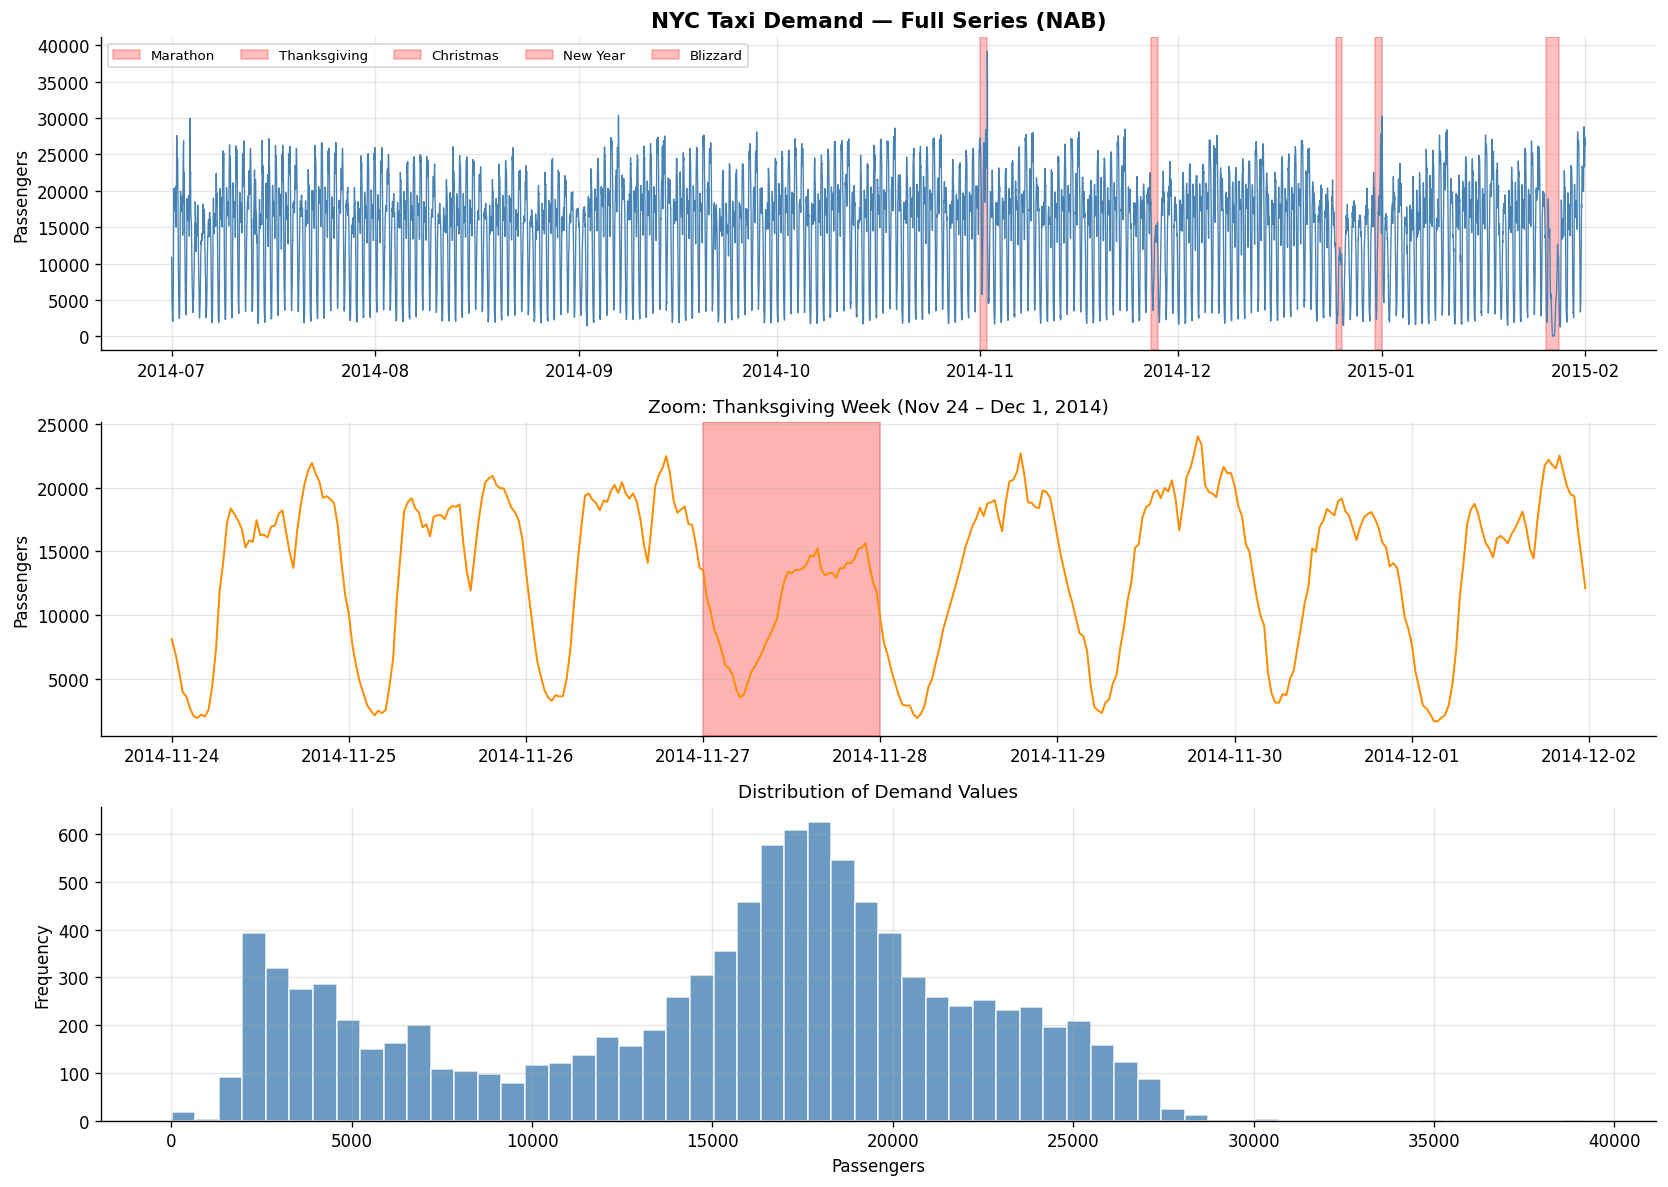

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# Full time series
axes[0].plot(series.index, series.values, color="steelblue", linewidth=0.8)
axes[0].set_title("NYC Taxi Demand — Full Series (NAB)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Passengers")

# Mark known anomaly periods
known_anomalies = [
    ("2014-11-01", "2014-11-02", "Marathon"),
    ("2014-11-27", "2014-11-28", "Thanksgiving"),
    ("2014-12-25", "2014-12-26", "Christmas"),
    ("2014-12-31", "2015-01-01", "New Year"),
    ("2015-01-26", "2015-01-28", "Blizzard"),
]
for start, end, label in known_anomalies:
    axes[0].axvspan(pd.Timestamp(start), pd.Timestamp(end),
                    alpha=0.25, color="red", label=label)
axes[0].legend(loc="upper left", fontsize=8, ncol=5)

# One week zoom
week_start = "2014-11-24"
week_end = "2014-12-01"
week = series[week_start:week_end]
axes[1].plot(week.index, week.values, color="darkorange", linewidth=1.2)
axes[1].set_title("Zoom: Thanksgiving Week (Nov 24 – Dec 1, 2014)", fontsize=11)
axes[1].set_ylabel("Passengers")
axes[1].axvspan(pd.Timestamp("2014-11-27"), pd.Timestamp("2014-11-28"),
                alpha=0.3, color="red")

# Distribution
axes[2].hist(series.values, bins=60, color="steelblue", edgecolor="white", alpha=0.8)
axes[2].set_title("Distribution of Demand Values", fontsize=11)
axes[2].set_xlabel("Passengers")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig("nyc_taxi_overview.png", bbox_inches="tight")
plt.show()

## Data Preprocessing

In [4]:
# Check for missing values
print(f"Missing values: {series.isna().sum()}")

# Fill any gaps using linear interpolation
series_clean = series.interpolate(method="time")

# Normalize signal to zero mean, unit variance
signal_raw = series_clean.values.astype(float)
signal_mean = signal_raw.mean()
signal_std  = signal_raw.std()
signal = (signal_raw - signal_mean) / signal_std

timestamps = series_clean.index
N = len(signal)
print(f"Signal length after preprocessing: {N} samples")

# Verify stationarity (Augmented Dickey-Fuller test)

adf_result = adfuller(signal, autolag="AIC")
print(f"\nAugmented Dickey-Fuller test:")
print(f"  ADF statistic : {adf_result[0]:.4f}")
print(f"  p-value       : {adf_result[1]:.4f}")
print(f"  {'Stationary (reject H0)' if adf_result[1] < 0.05 else 'Non-stationary (fail to reject H0)'}")

Missing values: 0
Signal length after preprocessing: 10320 samples

Augmented Dickey-Fuller test:
  ADF statistic : -10.7645
  p-value       : 0.0000
  Stationary (reject H0)


### Visualizing the Preprocessed Signal

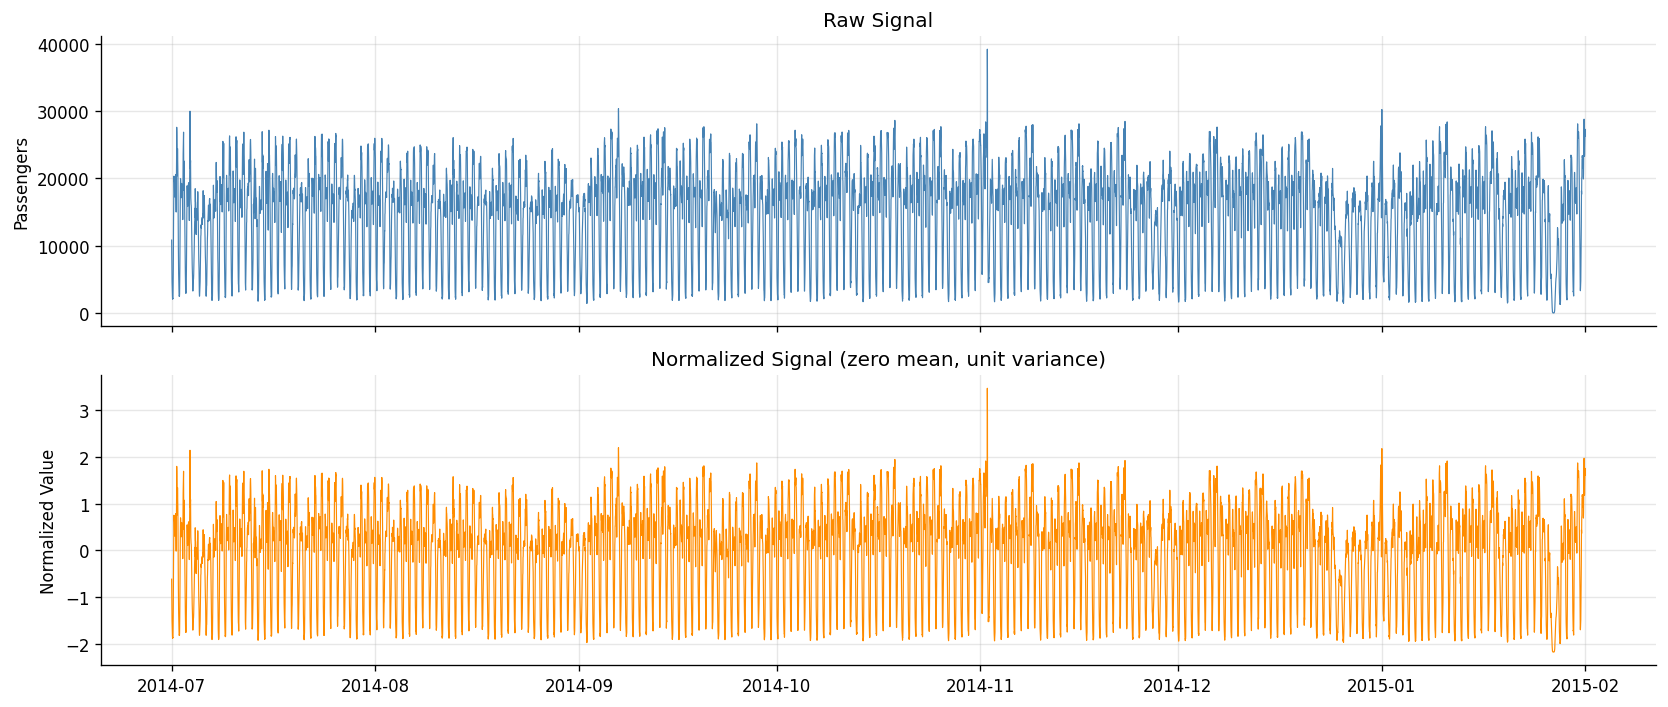

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].plot(timestamps, signal_raw, color="steelblue", linewidth=0.7, label="Raw")
axes[0].set_ylabel("Passengers")
axes[0].set_title("Raw Signal")

axes[1].plot(timestamps, signal, color="darkorange", linewidth=0.7, label="Normalized")
axes[1].set_ylabel("Normalized Value")
axes[1].set_title("Normalized Signal (zero mean, unit variance)")
plt.savefig("./output/passenger_signal_normalization.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

## Wavelet Decomposition

### Choosing the Decomposition Level

In [7]:
max_level = pywt.dwt_max_level(N, "db4")
print(f"Signal length     : {N}")
print(f"Maximum DWT level : {max_level}")

# At 30-min sampling, each level corresponds to:
level_periods = {j: (2**j * 30) for j in range(1, 7)}
print("\nApproximate period captured at each level (minutes):")
for j, p in level_periods.items():
    unit = "min" if p < 60 else ("hr" if p < 1440 else "day")
    val  = p if p < 60 else (p/60 if p < 1440 else p/1440)
    print(f"  Level {j}: ~{val:.1f} {unit}")

Signal length     : 10320
Maximum DWT level : 10

Approximate period captured at each level (minutes):
  Level 1: ~1.0 hr
  Level 2: ~2.0 hr
  Level 3: ~4.0 hr
  Level 4: ~8.0 hr
  Level 5: ~16.0 hr
  Level 6: ~1.3 day


### Performing the DWT

In [8]:
WAVELET = "db4"
LEVEL   = 5

coeffs = pywt.wavedec(signal, WAVELET, level=LEVEL)
A5, D5, D4, D3, D2, D1 = coeffs

print("Wavelet decomposition summary:")
print(f"  Wavelet     : {WAVELET}")
print(f"  Level       : {LEVEL}")
print(f"  Signal len  : {N}")
for i, c in enumerate(coeffs):
    label = f"A{LEVEL}" if i == 0 else f"D{LEVEL - i + 1}"
    print(f"  {label:3s} — length: {len(c):5d}  |  energy: {np.sum(c**2):.2f}")

Wavelet decomposition summary:
  Wavelet     : db4
  Level       : 5
  Signal len  : 10320
  A5  — length:   329  |  energy: 2007.68
  D5  — length:   329  |  energy: 5661.08
  D4  — length:   651  |  energy: 2516.90
  D3  — length:  1296  |  energy: 386.50
  D2  — length:  2585  |  energy: 128.17
  D1  — length:  5163  |  energy: 29.78


### Visualizing the Decomposition

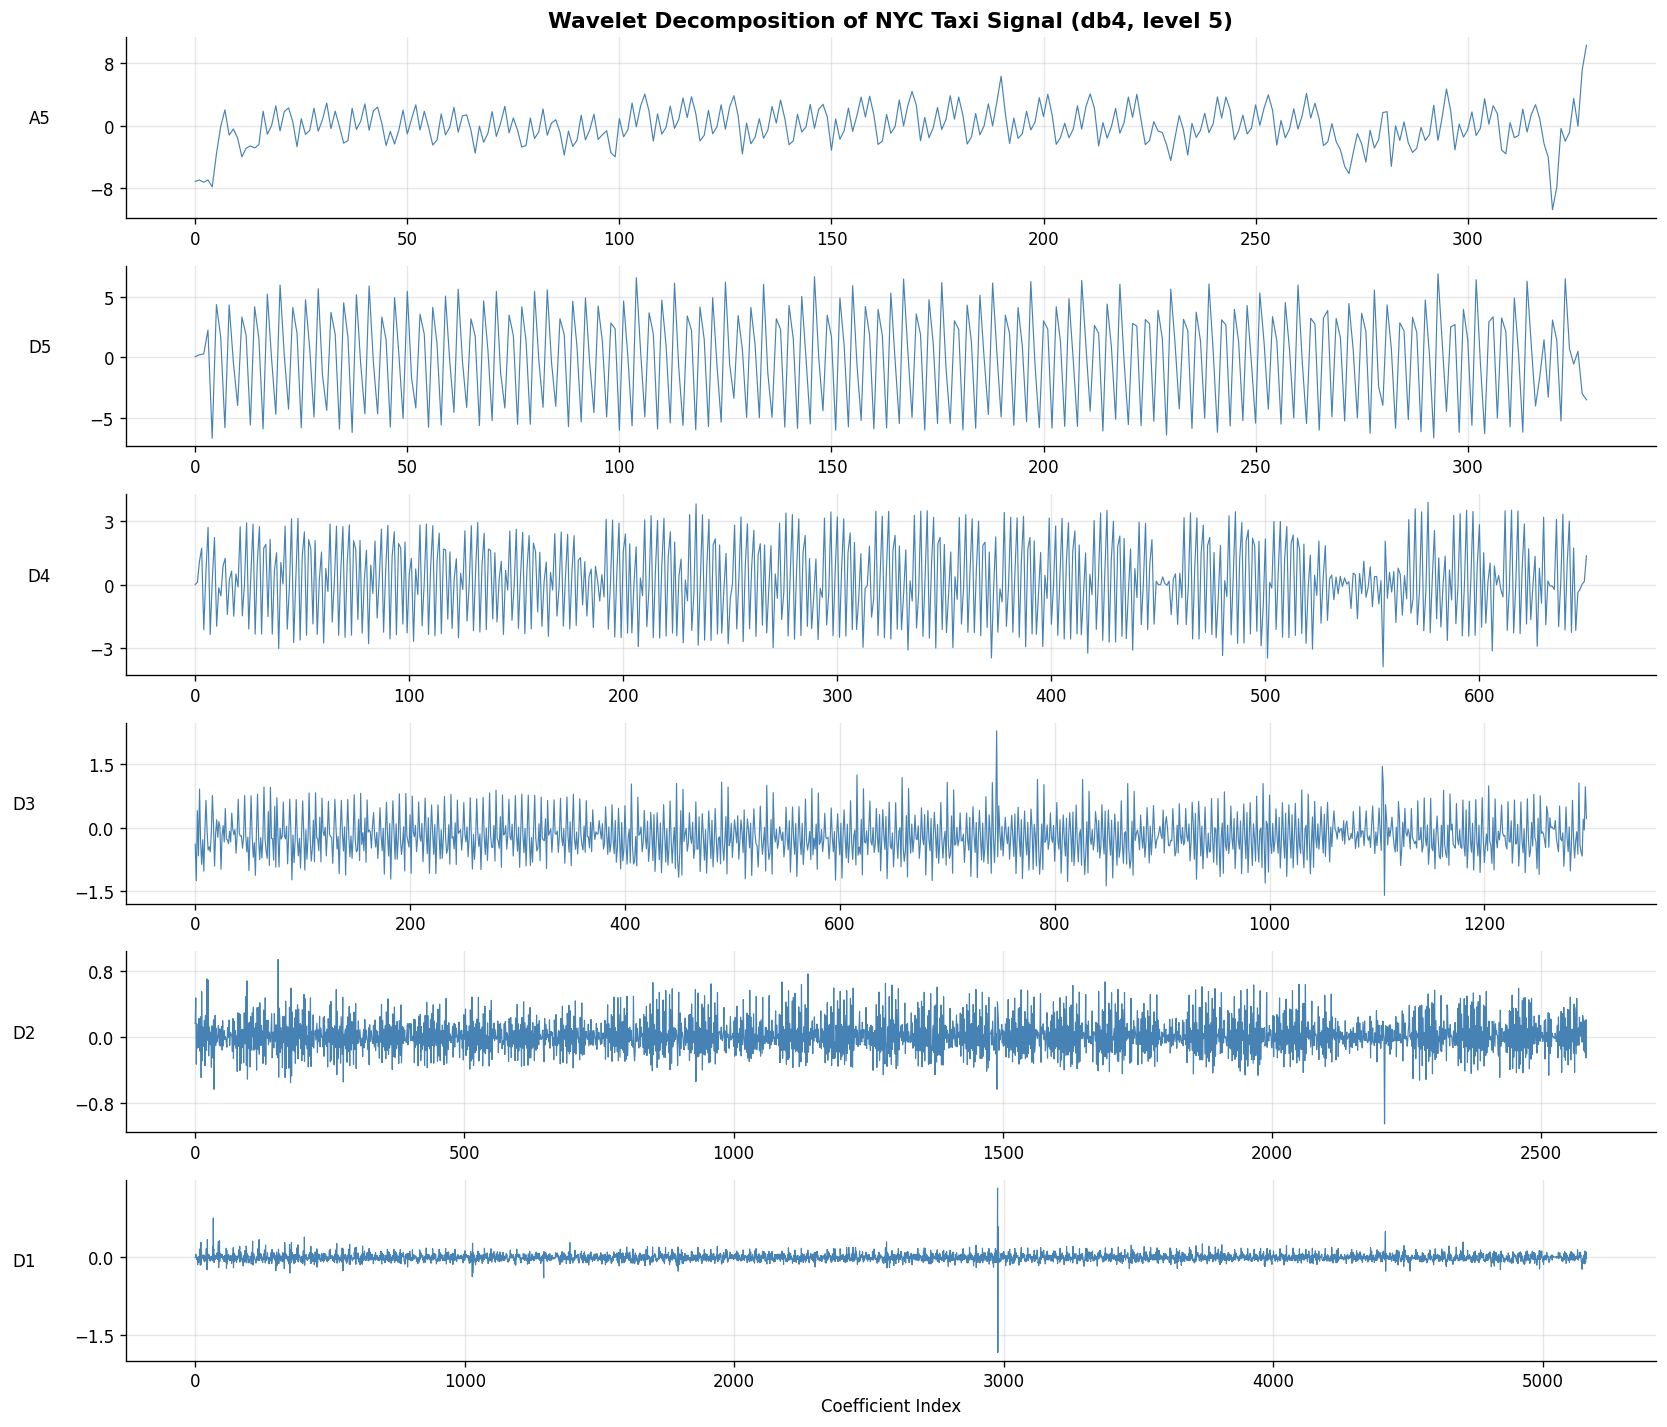

In [ ]:
labels = [f"A{LEVEL}"] + [f"D{j}" for j in range(LEVEL, 0, -1)]
fig, axes = plt.subplots(len(coeffs), 1, figsize=(14, 12), sharex=False)

for ax, coef, label in zip(axes, coeffs, labels):
    ax.plot(coef, linewidth=0.7, color="steelblue")
    ax.set_ylabel(label, rotation=0, labelpad=30, fontsize=10)
    ax.yaxis.set_major_locator(plt.MaxNLocator(3))

axes[0].set_title(
    f"Wavelet Decomposition of NYC Taxi Signal ({WAVELET}, level {LEVEL})",
    fontsize=13, fontweight="bold"
)
axes[-1].set_xlabel("Coefficient Index")
plt.tight_layout()
plt.savefig("./output/wavelet_decomposition.png", bbox_inches="tight")
plt.show()

### Scale-by-Scale Energy Analysis

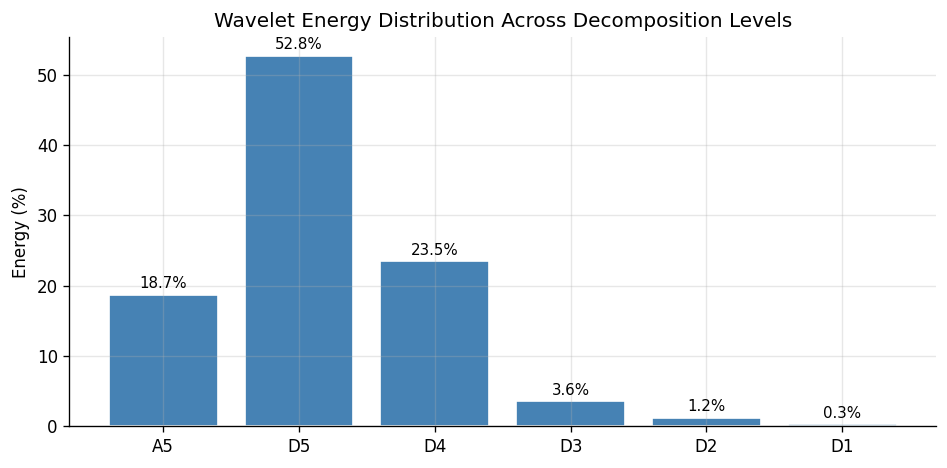

In [ ]:
energies = [np.sum(c**2) for c in coeffs]
total_energy = sum(energies)
energy_pct   = [100 * e / total_energy for e in energies]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, energy_pct, color="steelblue", edgecolor="white")
ax.set_ylabel("Energy (%)")
ax.set_title("Wavelet Energy Distribution Across Decomposition Levels")
for bar, pct in zip(bars, energy_pct):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f"{pct:.1f}%", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("./output/wavelet_energy_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## Anomaly Detection

### Sliding-Window Wavelet Energy Score


In [15]:
def wavelet_anomaly_score(signal, wavelet="db4", level=5, window=256):
    """
    Compute a sliding-window anomaly score from wavelet detail coefficients.

    Parameters
    ----------
    signal  : 1-D array-like, normalized input signal
    wavelet : str, wavelet family name
    level   : int, decomposition level
    window  : int, half-window size in samples

    Returns
    -------
    score : np.ndarray, anomaly score (same length as signal)
    """
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    detail_coeffs = coeffs[1:]   # exclude approximation

    N = len(signal)
    score = np.zeros(N)

    # Reconstruct each detail level to full signal length for alignment
    for j, d in enumerate(detail_coeffs):
        # Upsample detail coefficients back to original signal length
        rec_detail = pywt.upcoef("d", d, wavelet, level=j + 1, take=N)[:N]

        # Sliding window energy
        half_w = window // 2
        for t in range(N):
            lo = max(0, t - half_w)
            hi = min(N, t + half_w)
            local_energy = np.sum(rec_detail[lo:hi] ** 2)
            score[t] += local_energy

    # Normalize score to z-score
    score = (score - score.mean()) / (score.std() + 1e-8)
    return score


WINDOW_SIZE = 256
anomaly_score = wavelet_anomaly_score(signal, wavelet=WAVELET, level=LEVEL,
                                       window=WINDOW_SIZE)
print(f"Anomaly score — mean: {anomaly_score.mean():.3f}, "
      f"std: {anomaly_score.std():.3f}, "
      f"max: {anomaly_score.max():.3f}")

Anomaly score — mean: 0.000, std: 1.000, max: 4.365


### Applying the Detection Threshold

In [16]:
THRESHOLD = 2.5

anomaly_flags = anomaly_score > THRESHOLD
n_detected = np.sum(anomaly_flags)
print(f"Threshold    : {THRESHOLD} standard deviations")
print(f"Flagged points : {n_detected} / {len(signal)} ({100 * n_detected / len(signal):.2f}%)")

Threshold    : 2.5 standard deviations
Flagged points : 566 / 10320 (5.48%)


### Visualizing Wavelet Anomaly Scores

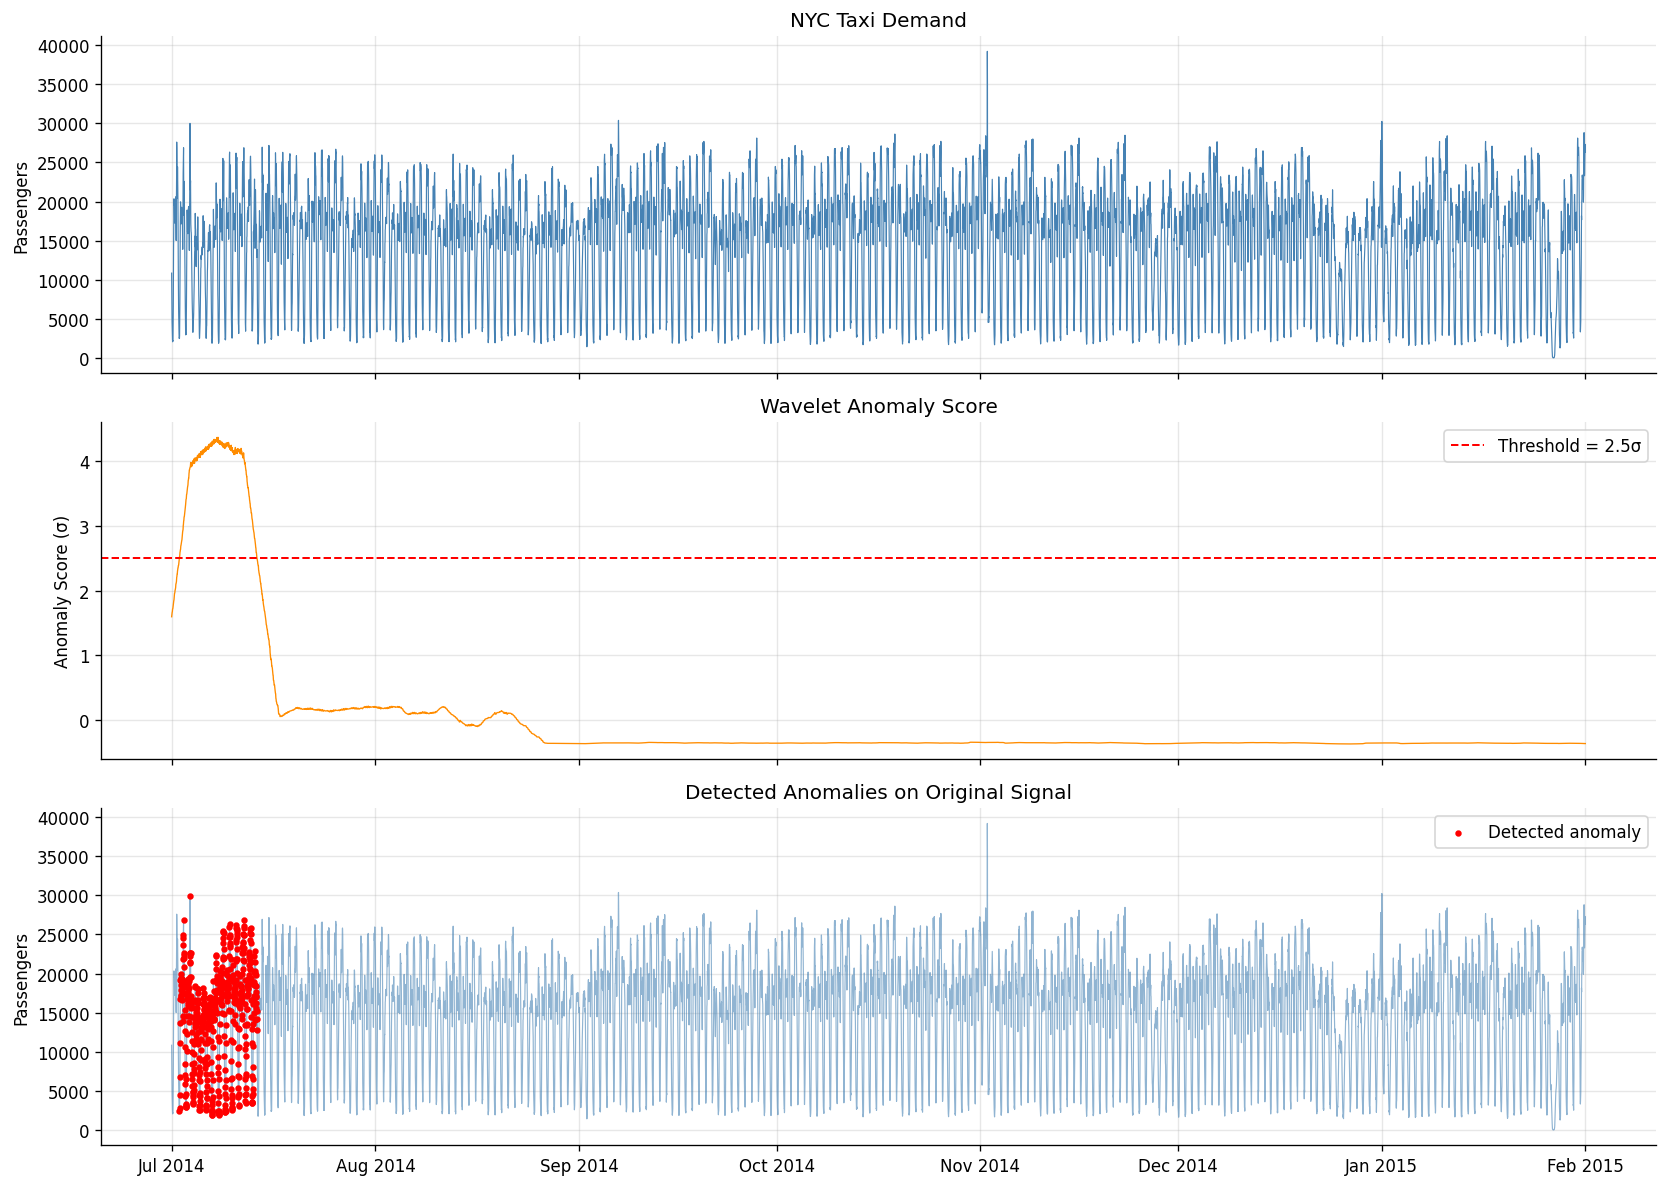

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Original signal
axes[0].plot(timestamps, signal_raw, color="steelblue", linewidth=0.7)
axes[0].set_ylabel("Passengers")
axes[0].set_title("NYC Taxi Demand", fontsize=12)

# Anomaly score
axes[1].plot(timestamps, anomaly_score, color="darkorange", linewidth=0.8)
axes[1].axhline(THRESHOLD, color="red", linestyle="--", linewidth=1.2,
                label=f"Threshold = {THRESHOLD}σ")
axes[1].set_ylabel("Anomaly Score (σ)")
axes[1].set_title("Wavelet Anomaly Score", fontsize=12)
axes[1].legend()

# Detected anomalies overlaid on signal
axes[2].plot(timestamps, signal_raw, color="steelblue", linewidth=0.7, alpha=0.6)
axes[2].scatter(timestamps[anomaly_flags], signal_raw[anomaly_flags],
                color="red", s=8, zorder=5, label="Detected anomaly")
axes[2].set_ylabel("Passengers")
axes[2].set_title("Detected Anomalies on Original Signal", fontsize=12)
axes[2].legend()
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.tight_layout()
plt.savefig("./output/wavelet_anomaly_detection.png", bbox_inches="tight")
plt.show()

## Comparison with Baseline Methods

### Z-Score Detection

In [20]:
def zscore_detector(signal, threshold=3.0):
    """Detect anomalies using global z-score thresholding."""
    z = (signal - np.mean(signal)) / np.std(signal)
    return np.abs(z) > threshold, z

zscore_flags, zscores = zscore_detector(signal, threshold=3.0)
print(f"Z-score detector: {np.sum(zscore_flags)} anomalies detected")

Z-score detector: 1 anomalies detected


### Moving Average Deviation

In [21]:
def moving_average_detector(signal, window=48, threshold=3.0):
    """
    Detect anomalies using deviation from a rolling mean.
    A window of 48 corresponds to one day at 30-min sampling.
    """
    series_tmp = pd.Series(signal)
    rolling_mean = series_tmp.rolling(window=window, center=True, min_periods=1).mean()
    rolling_std  = series_tmp.rolling(window=window, center=True, min_periods=1).std()
    deviation    = np.abs((series_tmp - rolling_mean) / (rolling_std + 1e-8))
    flags        = deviation > threshold
    return flags.values, deviation.values

ma_flags, ma_deviation = moving_average_detector(signal, window=48, threshold=3.0)
print(f"Moving-average detector: {np.sum(ma_flags)} anomalies detected")

Moving-average detector: 0 anomalies detected


### Isolation Forest

In [22]:
def isolation_forest_detector(signal, contamination=0.02):
    """
    Detect anomalies using Isolation Forest with lag features.
    """
    # Build feature matrix with lagged values
    lags = [1, 2, 3, 48, 96]   # 30-min, 1-hr, 1.5-hr, 1-day, 2-day lags
    X = pd.DataFrame({"value": signal})
    for lag in lags:
        X[f"lag_{lag}"] = X["value"].shift(lag)
    X = X.dropna()

    clf = IsolationForest(contamination=contamination, random_state=42, n_estimators=200)
    preds = clf.fit_predict(X.values)   # -1 = anomaly, 1 = normal
    scores = -clf.score_samples(X.values)

    flags = np.zeros(len(signal), dtype=bool)
    flags[len(signal) - len(preds):] = preds == -1

    full_scores = np.zeros(len(signal))
    full_scores[len(signal) - len(scores):] = scores
    return flags, full_scores

iforest_flags, iforest_scores = isolation_forest_detector(signal, contamination=0.02)
print(f"Isolation Forest: {np.sum(iforest_flags)} anomalies detected")

Isolation Forest: 205 anomalies detected


### Side-by-Side Comparison

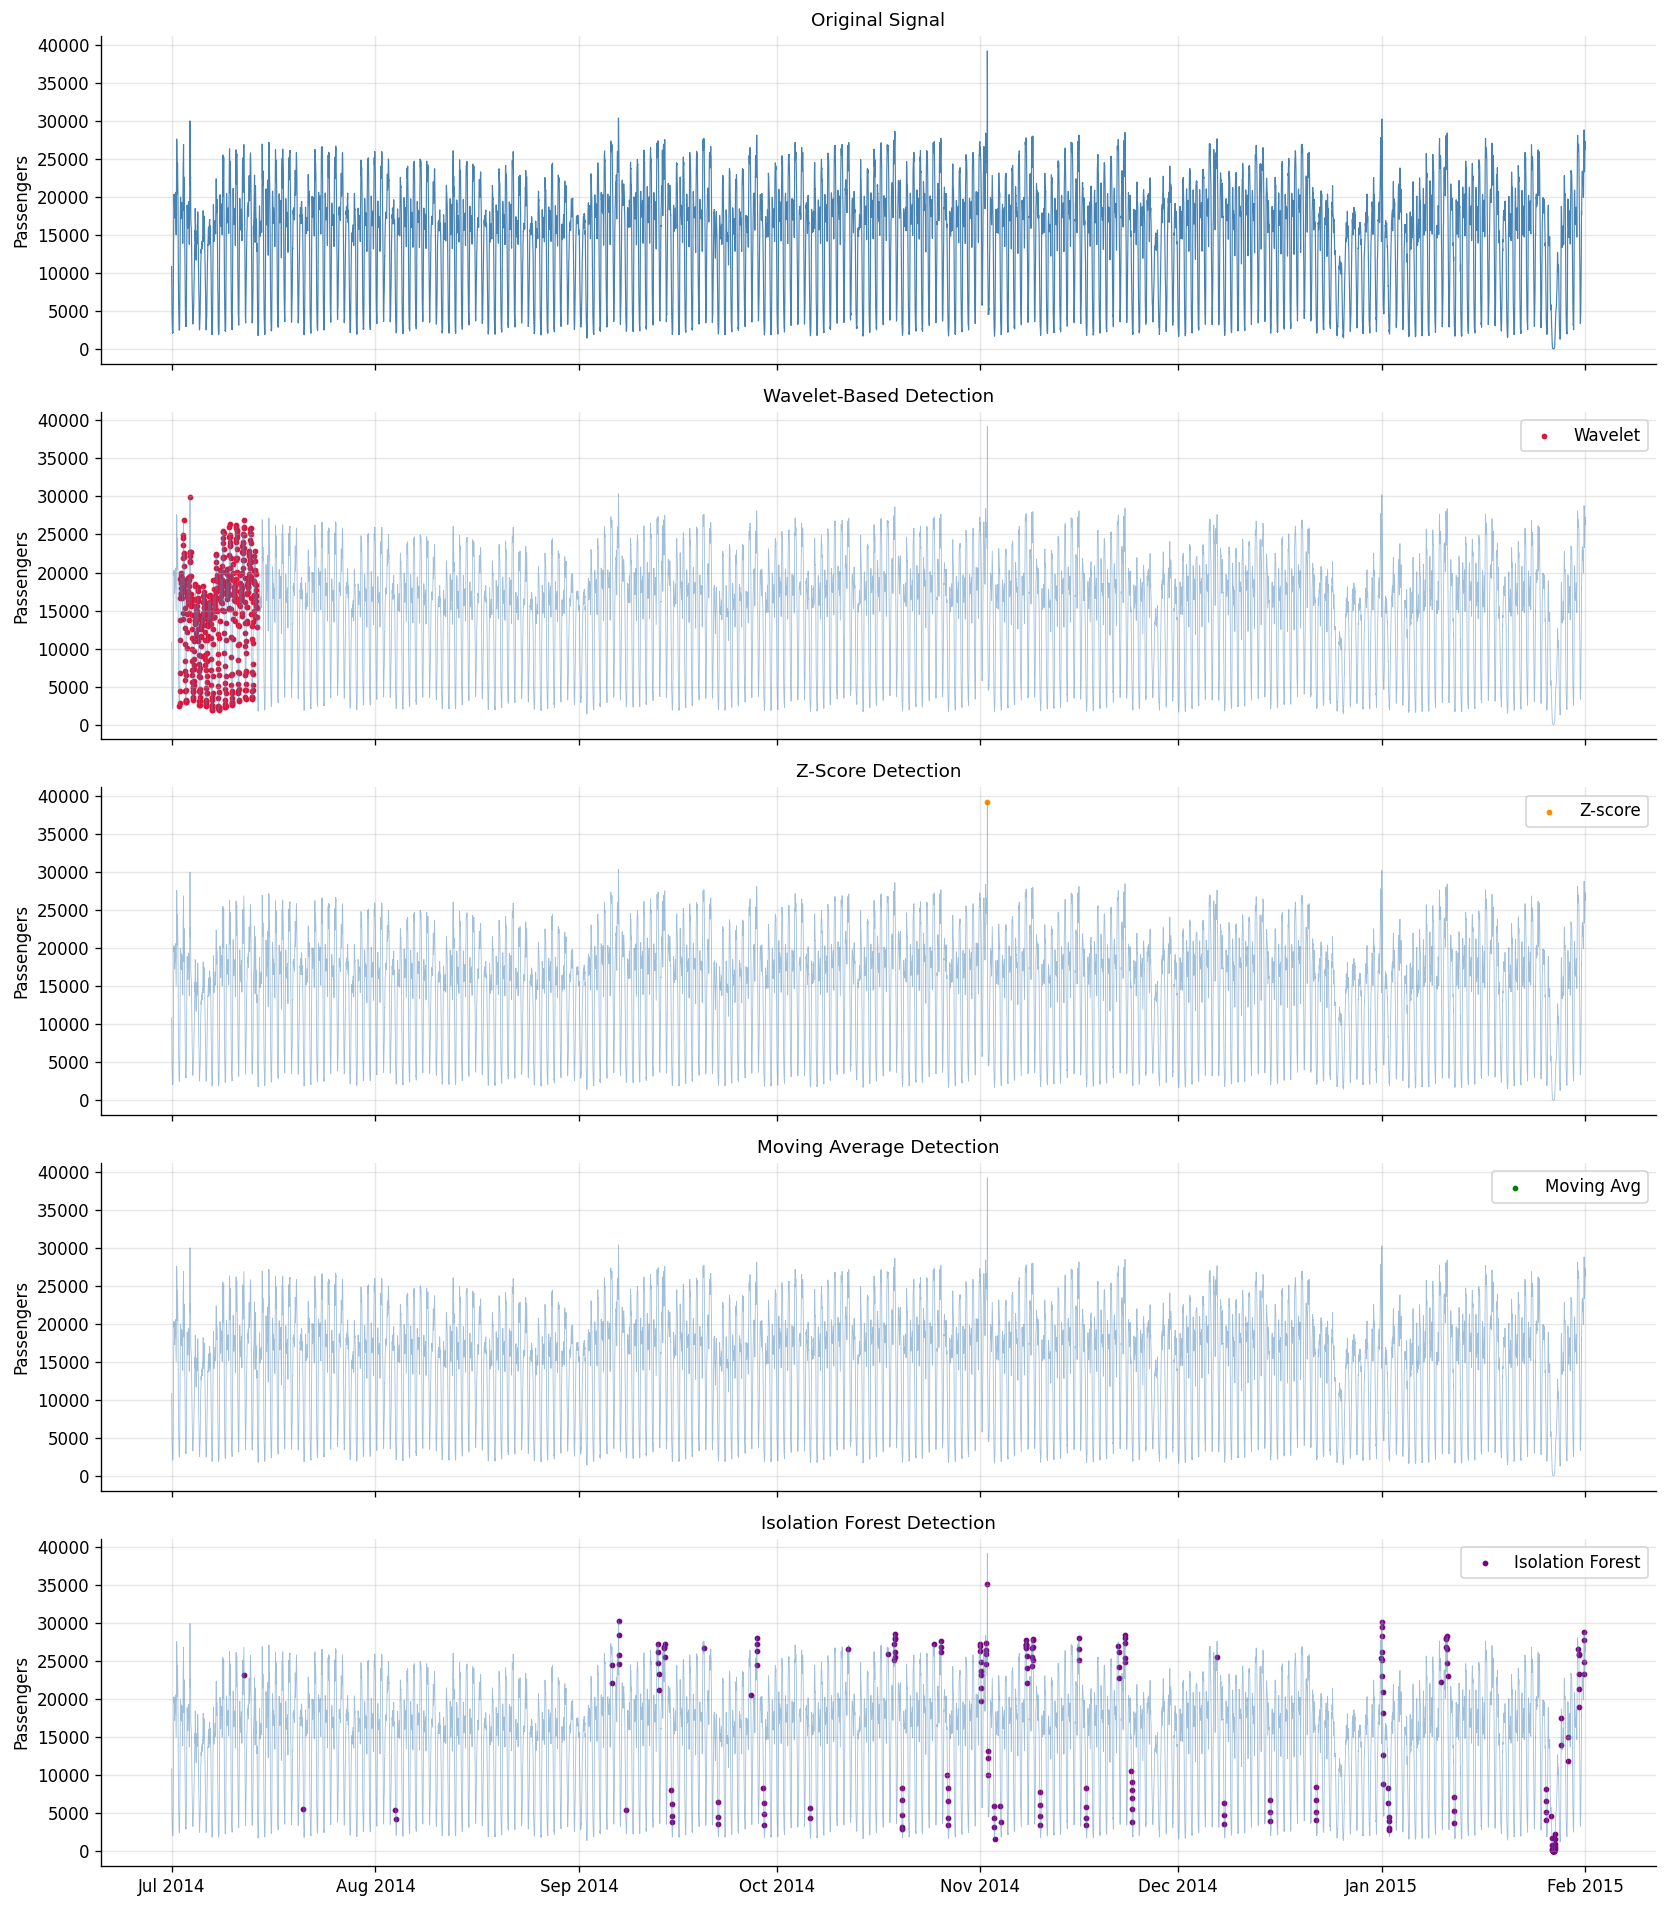

In [23]:
fig, axes = plt.subplots(5, 1, figsize=(14, 16), sharex=True)

# Signal
axes[0].plot(timestamps, signal_raw, color="steelblue", linewidth=0.7)
axes[0].set_ylabel("Passengers")
axes[0].set_title("Original Signal", fontsize=11)

# Wavelet
axes[1].plot(timestamps, signal_raw, color="steelblue", linewidth=0.5, alpha=0.5)
axes[1].scatter(timestamps[anomaly_flags], signal_raw[anomaly_flags],
                color="crimson", s=6, label="Wavelet")
axes[1].set_ylabel("Passengers")
axes[1].set_title("Wavelet-Based Detection", fontsize=11)
axes[1].legend()

# Z-score
axes[2].plot(timestamps, signal_raw, color="steelblue", linewidth=0.5, alpha=0.5)
axes[2].scatter(timestamps[zscore_flags], signal_raw[zscore_flags],
                color="darkorange", s=6, label="Z-score")
axes[2].set_ylabel("Passengers")
axes[2].set_title("Z-Score Detection", fontsize=11)
axes[2].legend()

# Moving average
axes[3].plot(timestamps, signal_raw, color="steelblue", linewidth=0.5, alpha=0.5)
axes[3].scatter(timestamps[ma_flags], signal_raw[ma_flags],
                color="green", s=6, label="Moving Avg")
axes[3].set_ylabel("Passengers")
axes[3].set_title("Moving Average Detection", fontsize=11)
axes[3].legend()

# Isolation Forest
axes[4].plot(timestamps, signal_raw, color="steelblue", linewidth=0.5, alpha=0.5)
axes[4].scatter(timestamps[iforest_flags], signal_raw[iforest_flags],
                color="purple", s=6, label="Isolation Forest")
axes[4].set_ylabel("Passengers")
axes[4].set_title("Isolation Forest Detection", fontsize=11)
axes[4].legend()
axes[4].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.tight_layout()
plt.savefig("method_comparison.png", bbox_inches="tight")
plt.show()


### Agreement Matrix

In [24]:
methods = {
    "Wavelet"          : anomaly_flags,
    "Z-score"          : zscore_flags,
    "Moving Average"   : ma_flags,
    "Isolation Forest" : iforest_flags,
}

# How many points does each method flag?
print("Detection summary:")
print(f"{'Method':<20} {'Flagged':>10} {'Rate (%)':>10}")
print("-" * 42)
for name, flags in methods.items():
    print(f"{name:<20} {np.sum(flags):>10} {100*np.mean(flags):>9.2f}%")

# Pairwise agreement (Jaccard similarity)
import itertools
names = list(methods.keys())
print("\nPairwise Jaccard Similarity (higher = more agreement):")
for a, b in itertools.combinations(names, 2):
    fa, fb = methods[a].astype(int), methods[b].astype(int)
    intersection = np.sum(fa & fb)
    union        = np.sum(fa | fb)
    jaccard      = intersection / union if union > 0 else 0
    print(f"  {a:<20} vs {b:<20}: {jaccard:.3f}")

Detection summary:
Method                  Flagged   Rate (%)
------------------------------------------
Wavelet                     566      5.48%
Z-score                       1      0.01%
Moving Average                0      0.00%
Isolation Forest            205      1.99%

Pairwise Jaccard Similarity (higher = more agreement):
  Wavelet              vs Z-score             : 0.000
  Wavelet              vs Moving Average      : 0.000
  Wavelet              vs Isolation Forest    : 0.001
  Z-score              vs Moving Average      : 0.000
  Z-score              vs Isolation Forest    : 0.000
  Moving Average       vs Isolation Forest    : 0.000


## Scale-Specific Anomaly Analysis

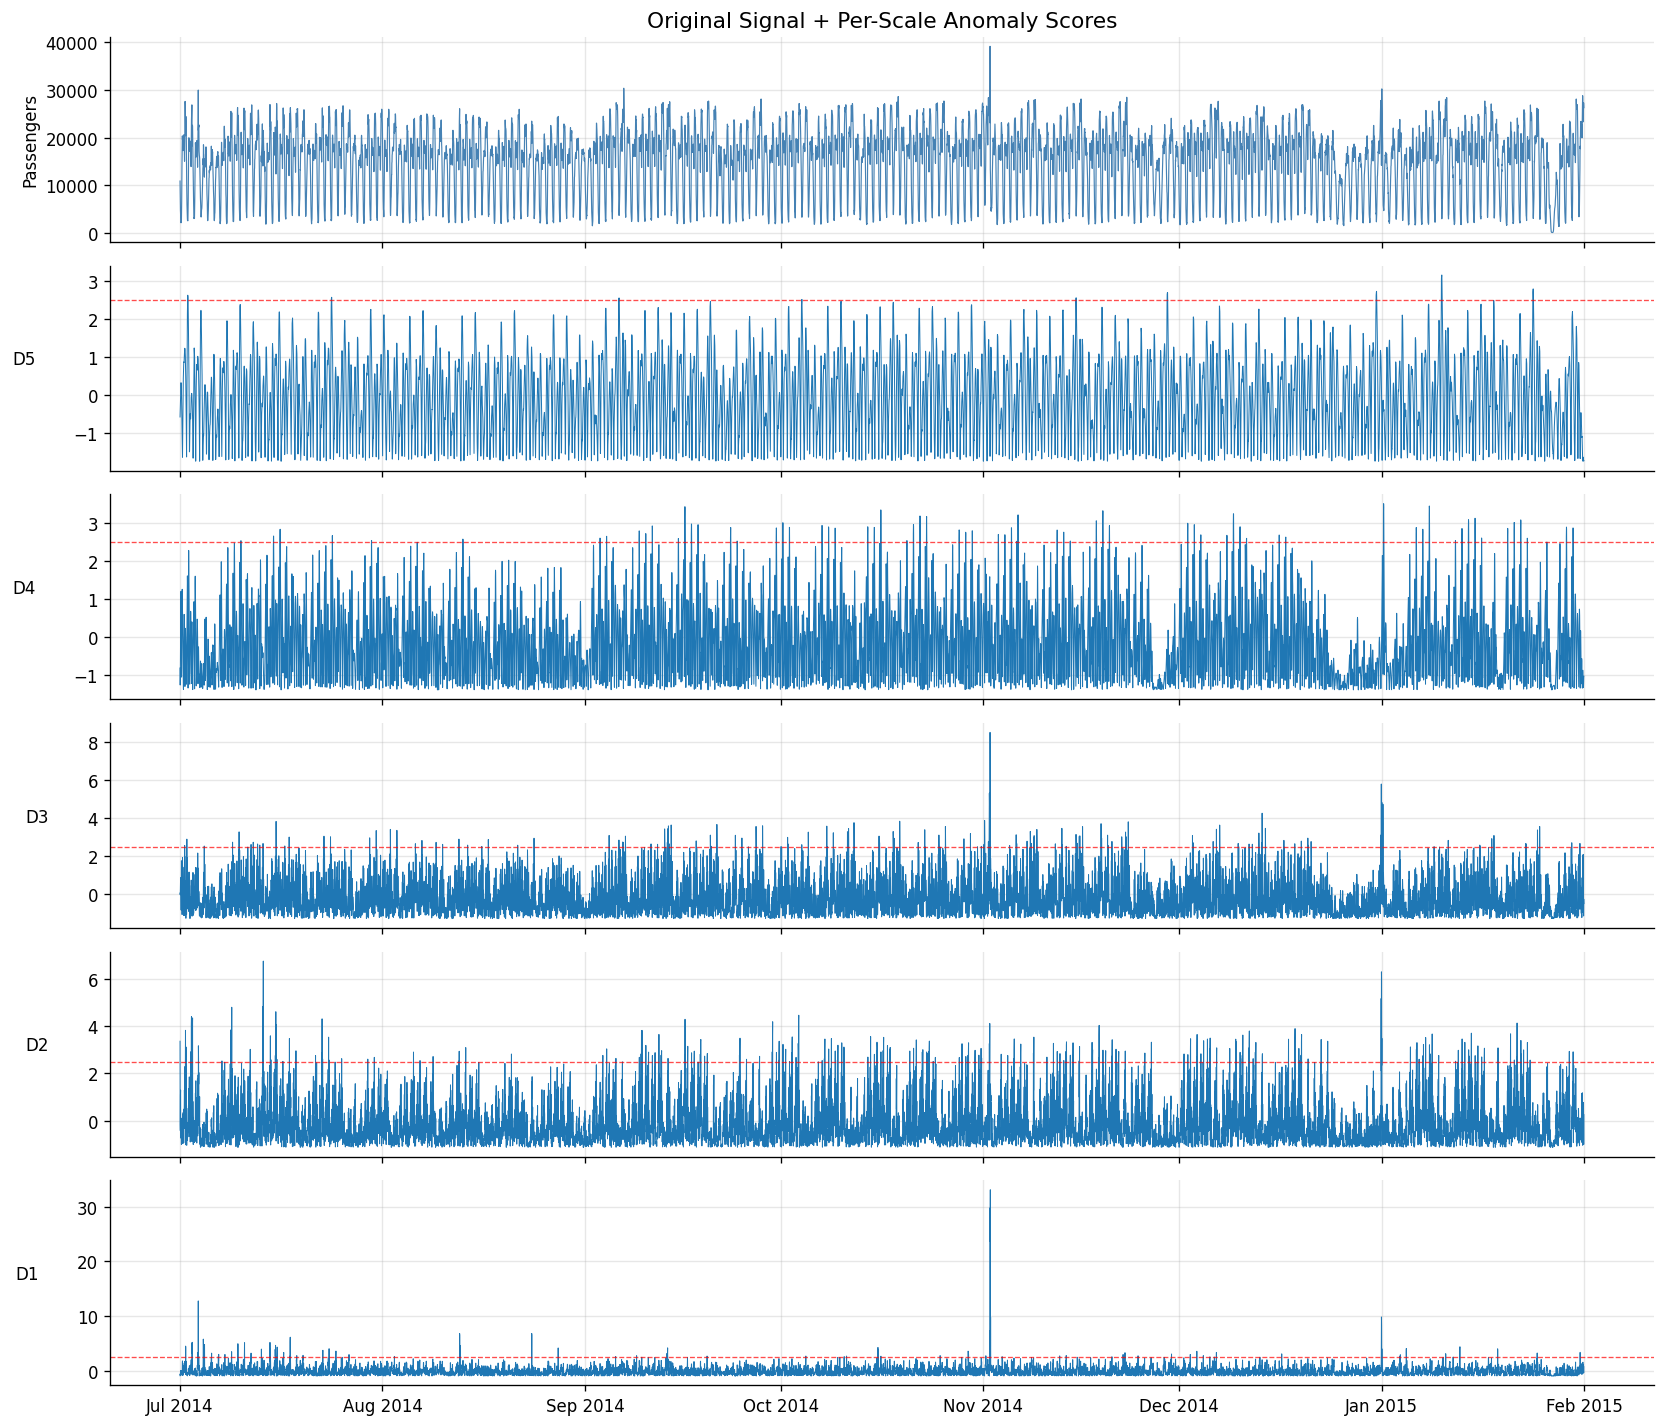

In [ ]:
def per_scale_scores(signal, wavelet="db4", level=5):
    """Return per-scale anomaly scores (z-scored absolute detail coefficients)."""
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    N = len(signal)
    scale_scores = {}
    
    for j in range(1, len(coeffs)):  # j=1 is finest detail (D1), j=level is coarsest
        # Build a coefficient list with zeros everywhere except level j
        isolated = [np.zeros_like(c) for c in coeffs]
        isolated[j] = coeffs[j]
        
        # Reconstruct to full signal length
        rec = pywt.waverec(isolated, wavelet)[:N]
        
        z = np.abs(rec)
        z = (z - z.mean()) / (z.std() + 1e-8)
        
        # Label: D5 = coarsest, D1 = finest
        scale_scores[f"D{level - j + 1}"] = z
    
    return scale_scores

scale_scores = per_scale_scores(signal)

fig, axes = plt.subplots(len(scale_scores) + 1, 1, figsize=(14, 12), sharex=True)

axes[0].plot(timestamps, signal_raw, color="steelblue", linewidth=0.7)
axes[0].set_title("Original Signal + Per-Scale Anomaly Scores", fontsize=13)
axes[0].set_ylabel("Passengers")

for ax, (scale_label, sc) in zip(axes[1:], scale_scores.items()):
    ax.plot(timestamps, sc, linewidth=0.6, label=scale_label)
    ax.axhline(2.5, color="red", linestyle="--", linewidth=0.8, alpha=0.7)
    ax.set_ylabel(scale_label, rotation=0, labelpad=30)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout()
plt.savefig("per_scale_scores.png", bbox_inches="tight")
plt.show()

## Soft Thresholding and Signal Denoising

Estimated noise sigma : 0.0598
Universal threshold   : 0.2572


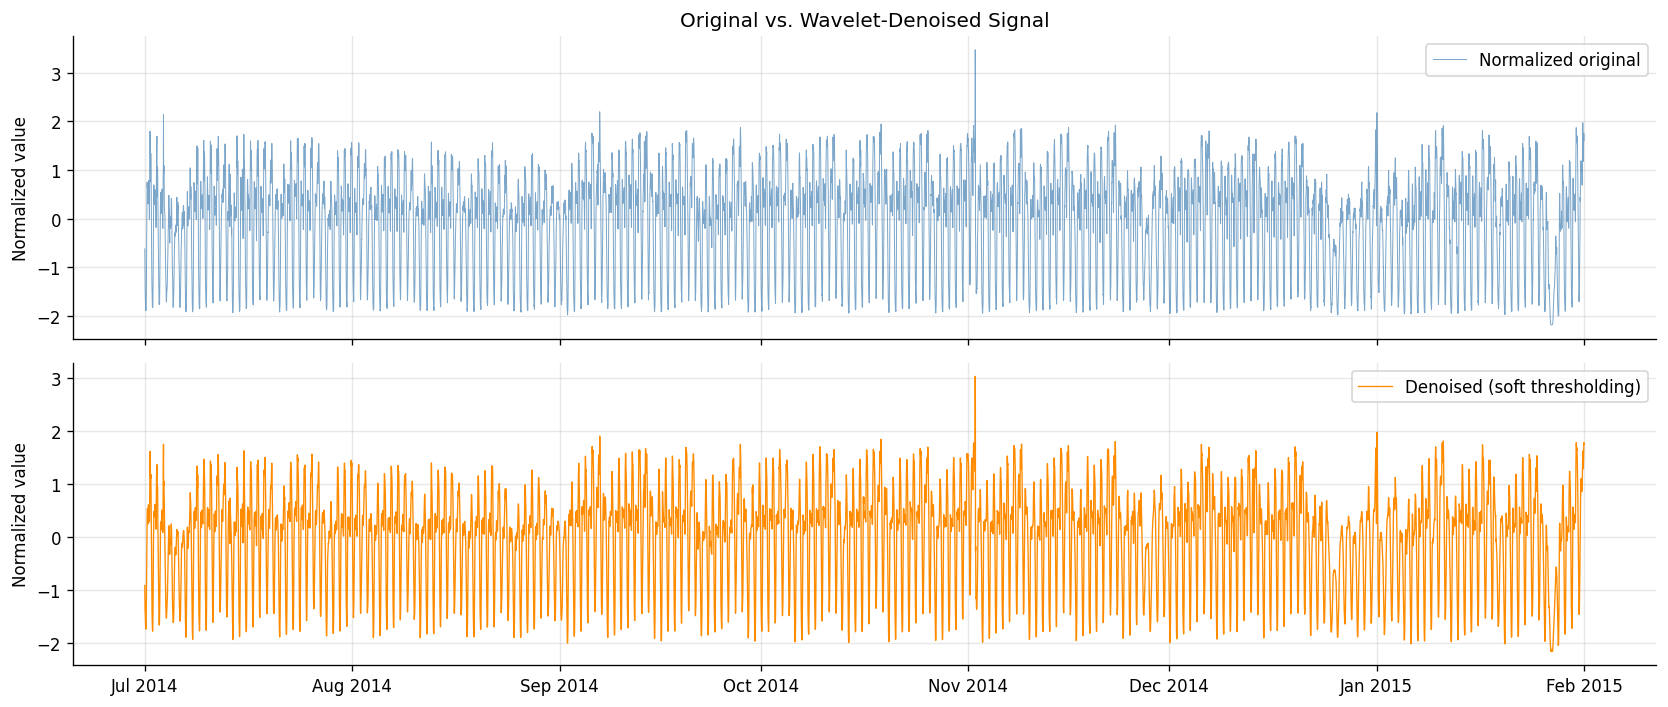

In [27]:
def soft_threshold_denoise(signal, wavelet="db4", level=5, mode="soft"):
    """
    Denoise a signal using wavelet soft thresholding (VisuShrink rule).

    The universal threshold is defined as:
        lambda = sigma * sqrt(2 * log(N))
    where sigma is estimated from the finest detail level.
    """
    N = len(signal)
    coeffs = pywt.wavedec(signal, wavelet, level=level)

    # Estimate noise standard deviation from finest detail (median absolute deviation)
    sigma = np.median(np.abs(coeffs[-1])) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(N))
    print(f"Estimated noise sigma : {sigma:.4f}")
    print(f"Universal threshold   : {threshold:.4f}")

    # Apply thresholding to detail coefficients only
    coeffs_thresh = [coeffs[0]] + [
        pywt.threshold(c, threshold, mode=mode) for c in coeffs[1:]
    ]
    denoised = pywt.waverec(coeffs_thresh, wavelet)[:N]
    return denoised, threshold

denoised_signal, univ_threshold = soft_threshold_denoise(signal)

# Plot original vs denoised
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(timestamps, signal, color="steelblue", linewidth=0.6, alpha=0.7,
             label="Normalized original")
axes[0].set_title("Original vs. Wavelet-Denoised Signal", fontsize=12)
axes[0].set_ylabel("Normalized value")
axes[0].legend()

axes[1].plot(timestamps, denoised_signal, color="darkorange", linewidth=0.8,
             label="Denoised (soft thresholding)")
axes[1].set_ylabel("Normalized value")
axes[1].legend()
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout()
plt.savefig("wavelet_denoised_signal.png", dpi=300, bbox_inches="tight")
plt.show()

## Evaluation

### Aligning Known Events with Detected Anomalies

In [24]:
# Define known anomaly windows
known_windows = [
    ("2014-11-01 00:00", "2014-11-02 00:00", "NYC Marathon"),
    ("2014-11-27 00:00", "2014-11-28 12:00", "Thanksgiving"),
    ("2014-12-25 00:00", "2014-12-26 00:00", "Christmas"),
    ("2014-12-31 12:00", "2015-01-01 12:00", "New Year's Eve"),
    ("2015-01-26 00:00", "2015-01-28 00:00", "Blizzard"),
]

print(f"{'Event':<25} {'Wavelet':>10} {'Z-score':>10} {'Mov.Avg':>10} {'IForest':>10}")
print("-" * 65)

for start_s, end_s, name in known_windows:
    mask = (timestamps >= pd.Timestamp(start_s)) & (timestamps <= pd.Timestamp(end_s))
    total = mask.sum()
    hits = {
        "Wavelet"  : anomaly_flags[mask].sum(),
        "Z-score"  : zscore_flags[mask].sum(),
        "Mov.Avg"  : ma_flags[mask].sum(),
        "IForest"  : iforest_flags[mask].sum(),
    }
    print(f"{name:<25} "
          + "  ".join(f"{v:>8}/{total}" for v in hits.values()))

Event                        Wavelet    Z-score    Mov.Avg    IForest
-----------------------------------------------------------------
NYC Marathon                     0/49         0/49         0/49         9/49
Thanksgiving                     0/73         0/73         0/73         0/73
Christmas                        0/49         0/49         0/49         0/49
New Year's Eve                   0/49         0/49         0/49        11/49
Blizzard                         0/97         0/97         0/97        25/97


### Receiver Operating Characteristic (ROC) Analysis

Total labeled anomaly points : 317 / 10320


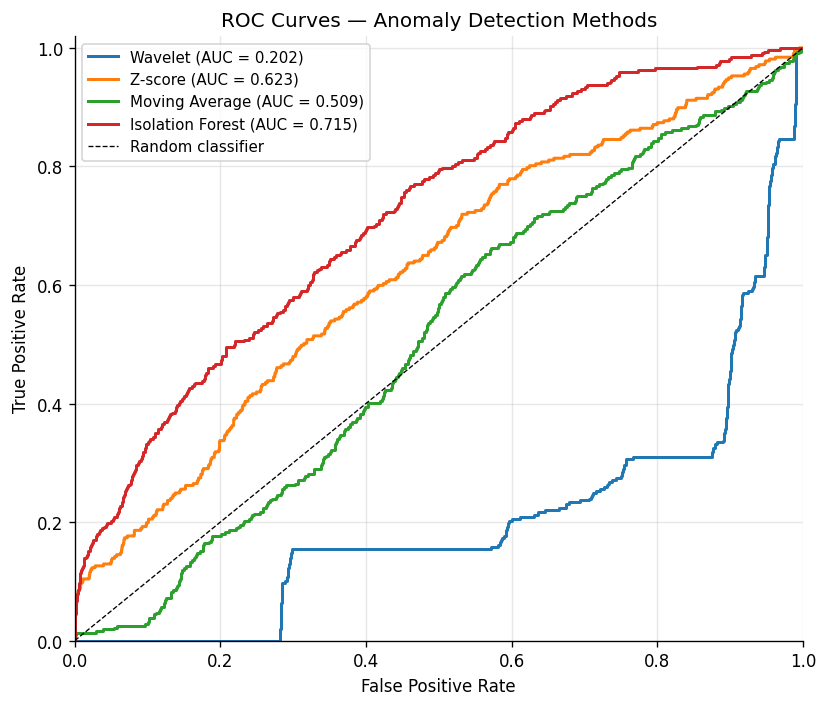

In [25]:
from sklearn.metrics import roc_curve, auc

# Build binary ground-truth labels (1 = known anomaly window)
y_true = np.zeros(len(signal), dtype=int)
for start_s, end_s, _ in known_windows:
    mask = (timestamps >= pd.Timestamp(start_s)) & (timestamps <= pd.Timestamp(end_s))
    y_true[mask] = 1

print(f"Total labeled anomaly points : {y_true.sum()} / {len(y_true)}")

# ROC for each method (continuous scores)
continuous_scores = {
    "Wavelet"          : anomaly_score,
    "Z-score"          : np.abs(zscores),
    "Moving Average"   : ma_deviation,
    "Isolation Forest" : iforest_scores,
}

fig, ax = plt.subplots(figsize=(7, 6))
for name, score in continuous_scores.items():
    fpr, tpr, _ = roc_curve(y_true, score)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, linewidth=1.8, label=f"{name} (AUC = {roc_auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", linewidth=0.8, label="Random classifier")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — Anomaly Detection Methods", fontsize=12)
ax.legend(fontsize=9)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
plt.tight_layout()
plt.savefig("roc_curves.png", bbox_inches="tight")
plt.show()

## Advanced: Continuous Wavelet Transform for Visualization

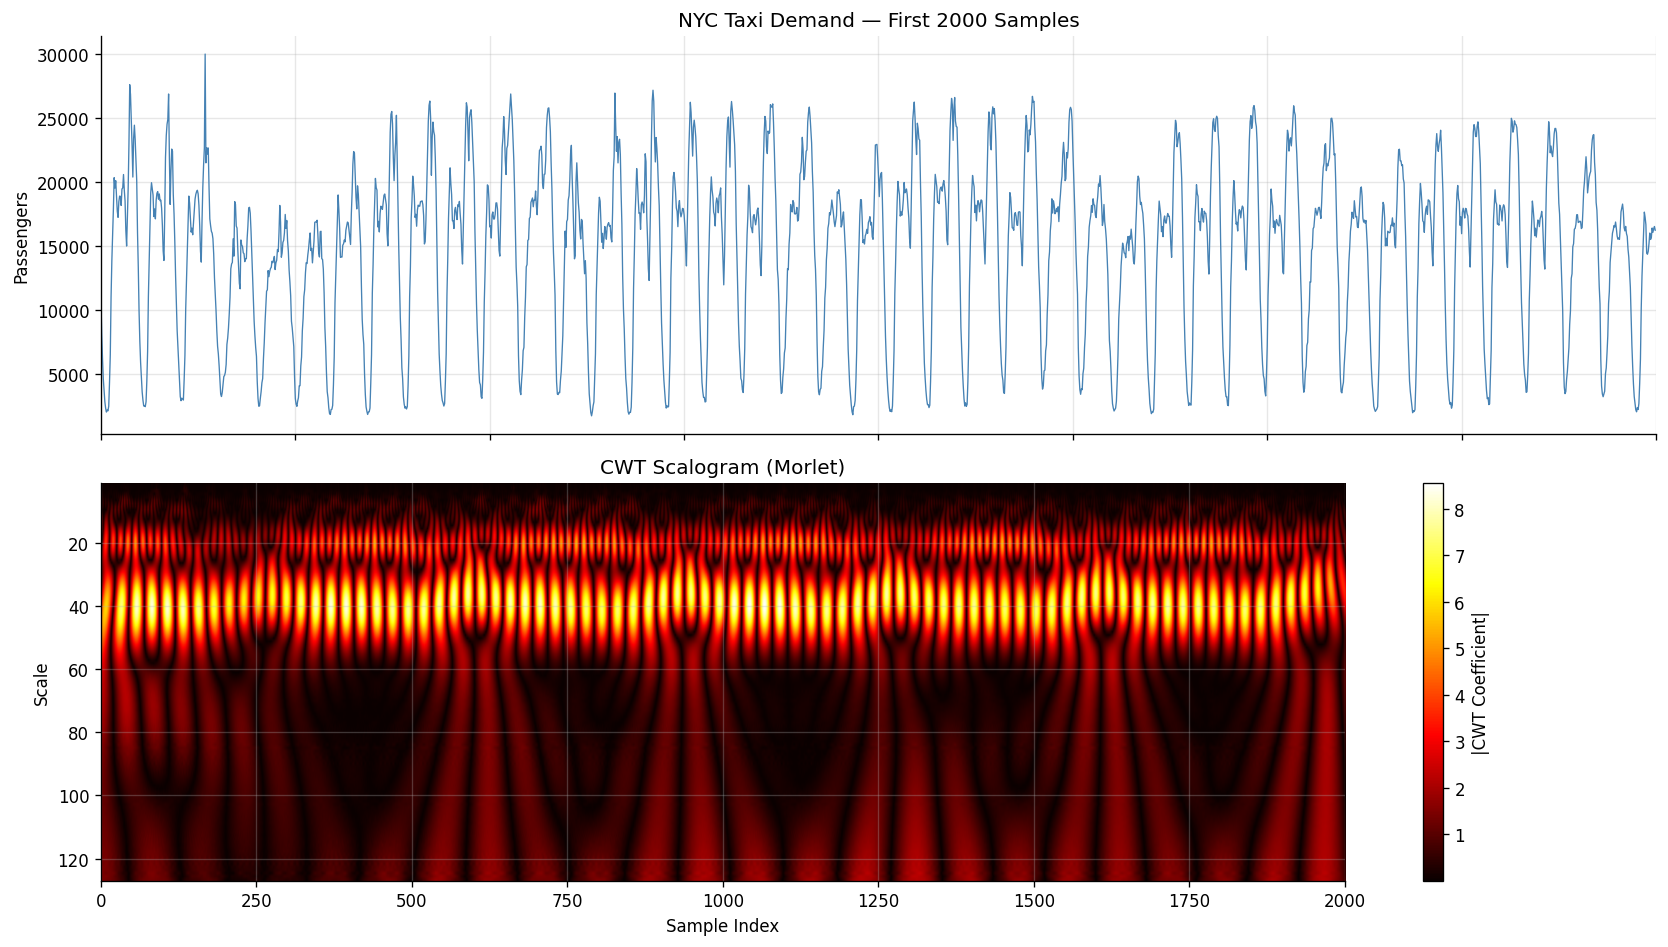

In [26]:
import pywt

# Compute CWT using the Morlet wavelet
scales = np.arange(1, 128)
wavelet_cwt = "morl"   # Morlet — good for oscillatory patterns
coefs, freqs = pywt.cwt(signal[:2000], scales, wavelet_cwt)   # use first 2000 pts

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(signal_raw[:2000], color="steelblue", linewidth=0.8)
axes[0].set_ylabel("Passengers")
axes[0].set_title("NYC Taxi Demand — First 2000 Samples", fontsize=12)

# Scalogram
im = axes[1].imshow(
    np.abs(coefs),
    extent=[0, 2000, scales[-1], scales[0]],
    aspect="auto",
    cmap="hot",
    interpolation="bilinear",
)
axes[1].set_ylabel("Scale")
axes[1].set_xlabel("Sample Index")
axes[1].set_title("CWT Scalogram (Morlet)", fontsize=12)
plt.colorbar(im, ax=axes[1], label="|CWT Coefficient|")

plt.tight_layout()
plt.savefig("cwt_scalogram.png", bbox_inches="tight")
plt.show()